# CIC-IDS-2017 - Exploratory Data Analysis

Source: `GeneratedLabelledFlows/TrafficLabelling` CSVs (identical feature values to `MachineLearningCVE`, plus timestamps and flow identifiers). Raw-file statistics come from the cleaning report written by `preprocessing/data_cleaning.py`; distributions are computed on the cleaned table. Charts are saved to `outputs/eda/` with a CSV table next to each figure.

Every number in the findings cells comes from the outputs printed directly above it.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'eda' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import pyarrow.parquet as pq
from IPython.display import Image, display
from utils.config import load_config, resolve_path
from preprocessing.preprocess import feature_columns, split_rows, signed_log1p
from eda import visualization as viz
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
cfg = load_config(); ds = cfg['datasets']['cicids2017']; SEED = cfg['project']['random_seed']
OUT = resolve_path(cfg['paths']['eda_dir']); OUT.mkdir(parents=True, exist_ok=True)
rep = json.loads(resolve_path(ds['cleaning_report']).read_text(encoding='utf-8'))
CLEAN = resolve_path(ds['clean_output'])

## 1. Dimensions and data types

In [2]:
pf = pq.ParquetFile(CLEAN)
schema = pf.schema_arrow
print(f"raw rows read: {rep['rows_read']:,} from {len(rep['per_file'])} files")
print(f"cleaned rows: {pf.metadata.num_rows:,}, columns: {len(schema)}")
print(pd.Series([str(t) for t in schema.types], index=schema.names).value_counts().to_string())
rows = pd.DataFrame({k: {'rows': v['rows']} for k, v in rep['per_file'].items()}).T
print(rows.to_string())

raw rows read: 2,830,743 from 8 files
cleaned rows: 2,498,103, columns: 81
float                    68
large_string              7
int32                     3
timestamp[us, tz=UTC]     1
int64                     1
int8                      1
                                                 rows
Monday-WorkingHours                            529918
Tuesday-WorkingHours                           445909
Wednesday-workingHours                         692703
Thursday-WorkingHours-Morning-WebAttacks       170366
Thursday-WorkingHours-Afternoon-Infilteration  288602
Friday-WorkingHours-Morning                    191033
Friday-WorkingHours-Afternoon-PortScan         286467
Friday-WorkingHours-Afternoon-DDos             225745


**Findings.** The 8 raw CSVs hold 2,830,743 flows. After cleaning, 2,498,103 rows and 81 columns remain:
68 numeric features (float32), the categorical inputs `dst_port` and `protocol`, the flow
identifiers, a UTC timestamp, `day`, and three label columns. Wednesday (692,703 raw rows) and
Monday (529,918) are the largest files.

## 2. Missing, infinite, negative and duplicate values (raw files)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


                          NaN  +-Inf  negative  negative -> NaN
Init_Win_bytes_backward     0      0   1441552                0
Init_Win_bytes_forward      0      0   1001189                0
Flow IAT Min                0      0      2891             2891
Flow IAT Mean               0      0       115              115
Flow Duration               0      0       115              115
Flow IAT Max                0      0       115              115
Flow Packets/s              0   2867       115              115
Flow Bytes/s             1358   1509        85               85
Fwd Header Length.1         0      0        35               35
min_seg_size_forward        0      0        35               35
Fwd Header Length           0      0        35               35
Bwd Header Length           0      0        22               22
Fwd IAT Min                 0      0        17               17

exact duplicate rows (features + label): 331,202 (11.70%)
conflicting duplicates (same features, differ

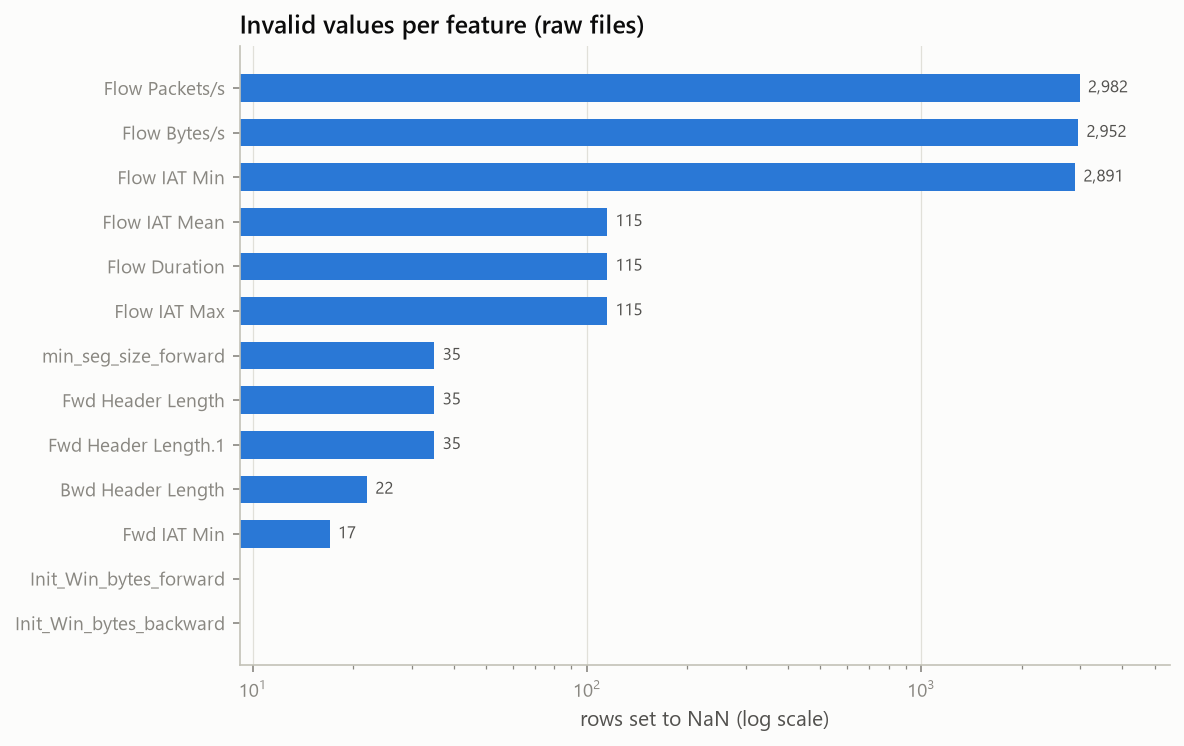

In [3]:
q = pd.DataFrame({'NaN': pd.Series(rep['nan_by_feature']), '+-Inf': pd.Series(rep['inf_by_feature']),
                  'negative': pd.Series(rep['negative_by_feature']),
                  'negative -> NaN': pd.Series(rep['negative_set_nan_by_feature'])}).fillna(0).astype(int)
print(q.sort_values('negative', ascending=False).to_string())
print()
print(f"exact duplicate rows (features + label): {rep['exact_duplicates_dropped']:,} "
      f"({rep['exact_duplicates_dropped'] / rep['rows_read']:.2%})")
print(f"conflicting duplicates (same features, different labels): {rep['conflicting_duplicate_rows']:,}")
print('conflicting rows by label:', rep['conflicting_rows_by_label'])
print('constant features dropped:', rep['constant_features_dropped'])
viz.bar_counts(q['NaN'] + q['+-Inf'] + q['negative -> NaN'], 'Invalid values per feature (raw files)',
               'rows set to NaN (log scale)', OUT / 'missing_values.png')
display(Image(OUT / 'missing_values.png'))

**Findings.** Missing values are rare and limited to rate features: `Flow Bytes/s` has 1,358 NaN and 1,509
infinite values, and `Flow Packets/s` has 2,867 infinite values (both rates are undefined when
the duration is 0). Negative values fall into two groups:

* `Init_Win_bytes_backward` (1,441,552 rows) and `Init_Win_bytes_forward` (1,001,189) are -1.
  This is a sentinel for "no TCP packet in that direction", so it was kept.
* Small numbers of impossible negatives: `Flow IAT Min` (2,891), `Flow Duration` and the Flow
  IAT Mean/Max (115 each), and header lengths (22-35). These were set to NaN and are imputed
  with training-set medians.

11.70% of rows (331,202) are exact duplicates of an earlier row. Another 7,144 rows are
*conflicting* duplicates: identical features with different labels, mostly DoS Hulk (5,317),
PortScan (1,053) and BENIGN (766). Their labels cannot be learned from the features, so they
were removed. 8 bulk/flag features are constant over the whole dataset and were dropped.

## 3. Label distribution and class imbalance

                                raw  after cleaning  removed %  share %
BENIGN                      2273097         2072959        8.8  82.9813
DoS Hulk                     231073          172699       25.3   6.9132
DDoS                         128027          128013        0.0   5.1244
PortScan                     158930           90255       43.2   3.6129
DoS GoldenEye                 10293           10282        0.1   0.4116
FTP-Patator                    7938            5933       25.3   0.2375
DoS slowloris                  5796            5372        7.3   0.2150
DoS Slowhttptest               5499            5228        4.9   0.2093
SSH-Patator                    5897            3219       45.4   0.1289
Bot                            1966            1953        0.7   0.0782
Web Attack - Brute Force       1507            1470        2.5   0.0588
Web Attack - XSS                652             652        0.0   0.0261
Infiltration                     36              36        0.0  

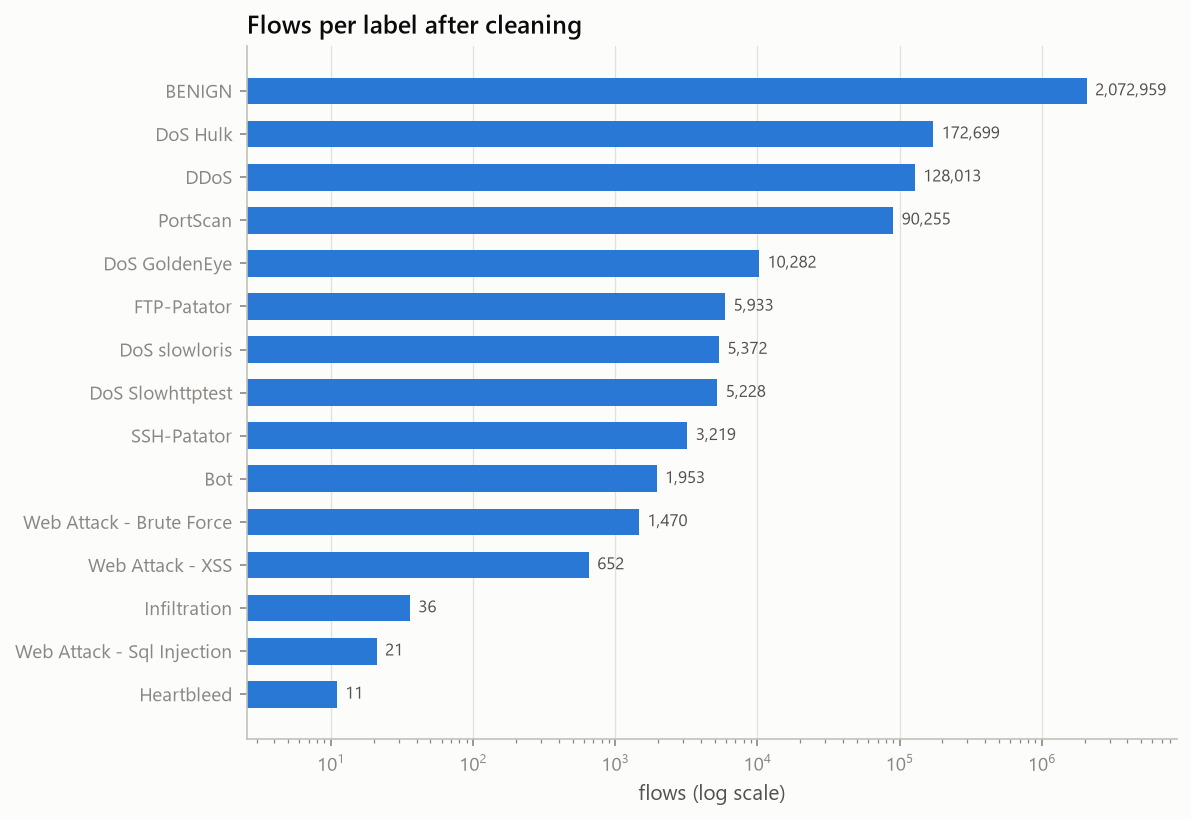

In [4]:
lab = pd.DataFrame({'raw': pd.Series(rep['labels_before']), 'after cleaning': pd.Series(rep['labels_after'])}).fillna(0).astype(int)
lab['removed %'] = (1 - lab['after cleaning'] / lab['raw']).mul(100).round(1)
lab['share %'] = (lab['after cleaning'] / lab['after cleaning'].sum() * 100).round(4)
print(lab.sort_values('after cleaning', ascending=False).to_string())
after = lab['after cleaning']
print(f"\nattack share: {1 - after['BENIGN'] / after.sum():.2%}; imbalance BENIGN : smallest class = {after.max() / after.min():,.0f} : 1")
viz.bar_counts(after, 'Flows per label after cleaning', 'flows (log scale)', OUT / 'class_distribution.png')
display(Image(OUT / 'class_distribution.png'))

**Findings.** The data is strongly imbalanced. BENIGN is 82.98% of cleaned flows and attacks are 17.02%.
The largest-to-smallest class ratio is 188,451 : 1 (BENIGN vs Heartbleed with 11 flows).
Infiltration (36) and Web Attack - Sql Injection (21) are similarly tiny. Deduplication hits
some classes much harder than others:

* PortScan loses 43.2% of its rows and SSH-Patator 45.4%. Many probe and login flows are
  byte-identical.
* DDoS, Web Attack - XSS, Infiltration and Heartbleed lose nothing.

Per-class metrics for the three smallest classes rest on 2-7 test flows each (see the split
report), so they cannot be estimated reliably.

## 4. Attack distribution by family and capture day

day                         Tuesday  Wednesday  Thursday  Friday
label                                                           
Bot                               0          0         0    1953
DDoS                              0          0         0  128013
DoS GoldenEye                     0      10282         0       0
DoS Hulk                          0     172699         0       0
DoS Slowhttptest                  0       5228         0       0
DoS slowloris                     0       5372         0       0
FTP-Patator                    5933          0         0       0
Heartbleed                        0         11         0       0
Infiltration                      0          0        36       0
PortScan                          0          0         0   90255
SSH-Patator                    3219          0         0       0
Web Attack - Brute Force          0          0      1470       0
Web Attack - Sql Injection        0          0        21       0
Web Attack - XSS         

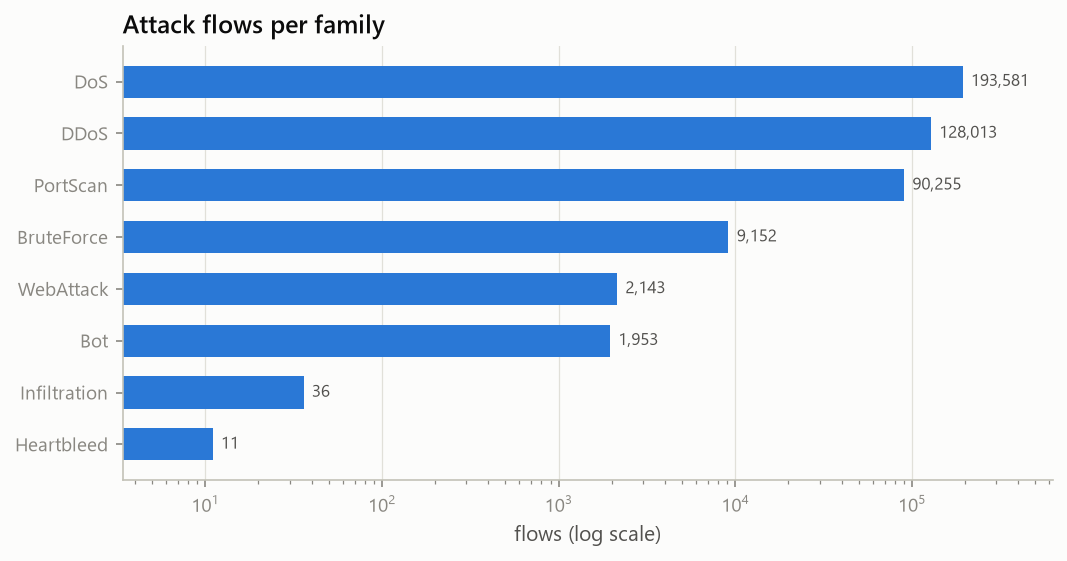

In [5]:
meta = pd.read_parquet(CLEAN, columns=['day', 'label', 'label_group', 'label_binary', 'timestamp'])
att = meta[meta.label_binary == 1]
by_day = pd.crosstab(att.label, att.day)[['Tuesday', 'Wednesday', 'Thursday', 'Friday']]
print(by_day.to_string())
print()
print(meta.groupby('day', sort=False).agg(flows=('label', 'size'), attack_share=('label_binary', 'mean')).round(4).to_string())
viz.bar_counts(att.label_group.value_counts(), 'Attack flows per family', 'flows (log scale)', OUT / 'attack_distribution.png')
display(Image(OUT / 'attack_distribution.png'))

**Findings.** Every attack type occurs on a single day only:

* Tuesday: FTP/SSH-Patator
* Wednesday: all DoS variants and Heartbleed
* Thursday: Web attacks and Infiltration
* Friday: Bot, PortScan and DDoS

Monday is purely BENIGN. Attack share per day ranges from 0% (Monday) and 0.55% (Thursday)
to 32.6% (Wednesday) and 37.2% (Friday). Two consequences follow:

* A day-based split puts entirely different attack types in train and test. This is the right
  setup for evaluating unseen attacks, but a multi-class model cannot learn the test classes.
* A random split mixes flows from the same attack burst into train and test, which inflates
  scores.

## 5. Analysis sample

Distribution plots use a label-capped sample: up to 30,000 flows per label (all flows of rarer labels), drawn with a fixed seed. Rates are therefore *per class*, not dataset-wide.

In [6]:
cols = [c for c in pq.ParquetFile(CLEAN).schema_arrow.names if c not in ('flow_id', 'src_ip', 'dst_ip', 'src_port')]
df = pd.read_parquet(CLEAN, columns=cols)  # identifiers not needed for EDA (saves memory)
FEATS = feature_columns(df)
def capped_sample(d, cap, by='label'):
    return pd.concat([g.sample(min(len(g), cap), random_state=SEED) for _, g in d.groupby(by)])
sample = capped_sample(df, 30000)
print(f'numeric features: {len(FEATS)}; sample rows: {len(sample):,}')
print(sample.label.value_counts().to_string())

numeric features: 68; sample rows: 154,177
label
BENIGN                        30000
DDoS                          30000
DoS Hulk                      30000
PortScan                      30000
DoS GoldenEye                 10282
FTP-Patator                    5933
DoS slowloris                  5372
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1953
Web Attack - Brute Force       1470
Web Attack - XSS                652
Infiltration                     36
Web Attack - Sql Injection       21
Heartbleed                       11


## 6. Feature distributions: packet size and flow duration

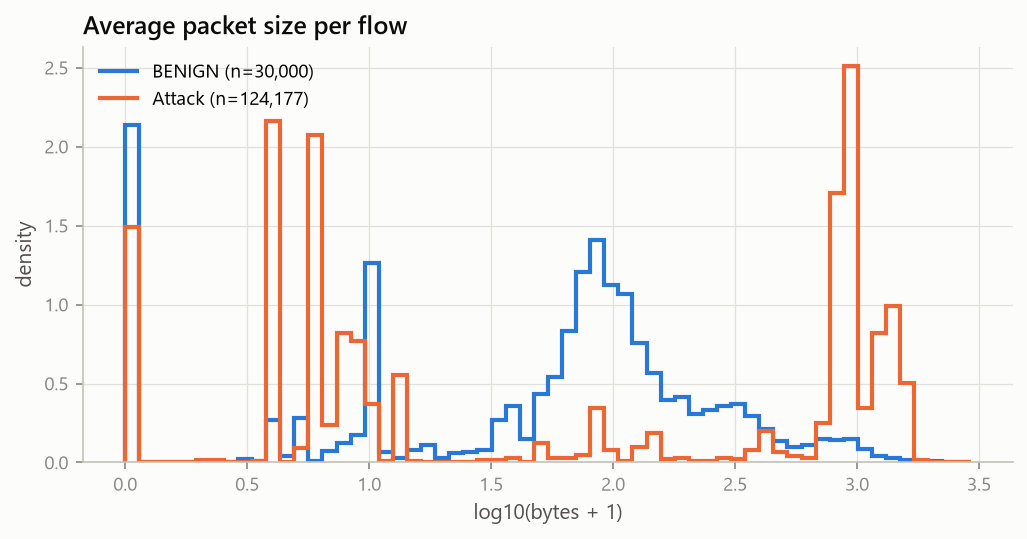

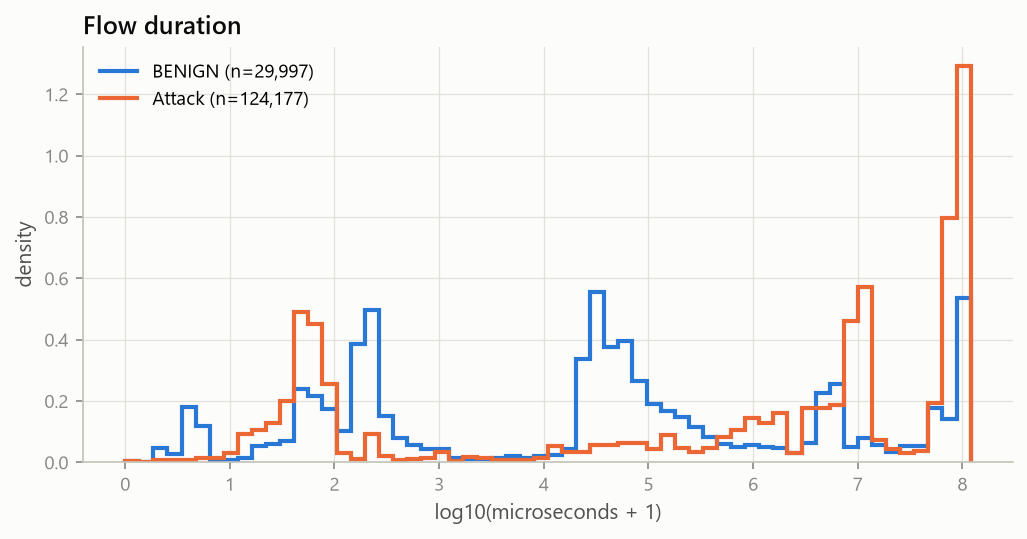

average_packet_size
label
DoS Slowhttptest                 0.000000
Web Attack - XSS                 0.000000
Web Attack - Brute Force         0.000000
PortScan                         3.000000
DoS slowloris                    6.000000
Bot                              9.000000
FTP-Patator                     12.125000
BENIGN                          79.000000
SSH-Patator                     89.679245
Web Attack - Sql Injection     131.625000
Infiltration                   146.777924
DoS GoldenEye                  513.028442
DDoS                           898.076904
DoS Hulk                       918.153870
Heartbleed                    1620.386597

flow_duration
label
PortScan                             50.0
BENIGN                            46323.0
Bot                               70987.0
DDoS                            1875323.0
Web Attack - Sql Injection      5006127.0
Web Attack - XSS                5398909.5
Web Attack - Brute Force        5567834.5
FTP-Patator                  

In [7]:
viz.hist_compare(sample, 'average_packet_size', OUT / 'packet_size_distribution.png',
                 'Average packet size per flow', 'log10(bytes + 1)')
viz.hist_compare(sample, 'flow_duration', OUT / 'flow_duration_distribution.png',
                 'Flow duration', 'log10(microseconds + 1)')
display(Image(OUT / 'packet_size_distribution.png')); display(Image(OUT / 'flow_duration_distribution.png'))
for c in ['average_packet_size', 'flow_duration']:
    print(c); print(sample.groupby('label')[c].median().sort_values().to_string()); print()
print('share of flows with duration < 1 ms by class:')
print((sample.flow_duration < 1000).groupby(sample.label).mean().round(3).sort_values().to_string())

**Findings.** The two classes differ strongly in timing and size:

* **PortScan** flows are almost instantaneous: median duration 50 us, 99.4% shorter than 1 ms.
  BENIGN has a median of 46,323 us, and 34.5% of BENIGN flows are under 1 ms.
* **Slow DoS** (slowloris median 99,999,408 us, Slowhttptest 63,120,444 us), **DoS Hulk**
  (86,680,684 us) and **Heartbleed** flows sit near the 120 s flow-timeout ceiling.
* **Packet size:** median average packet size is 0 bytes for DoS Slowhttptest and Web Attack
  Brute Force/XSS and 3 bytes for PortScan. BENIGN is 79 bytes. DoS Hulk (918), DDoS (898) and
  Heartbleed (1,620) are much larger.

These attack-specific modes are visible as separate peaks in the duration histogram. Note that
the "Attack" curve is a label-capped mix, so its shape is not weighted by attack prevalence.

## 7. Correlation matrix

Pearson correlation on `sign(x)*log1p(|x|)`-transformed features (the same transform the pipeline applies), computed on the label-capped sample.

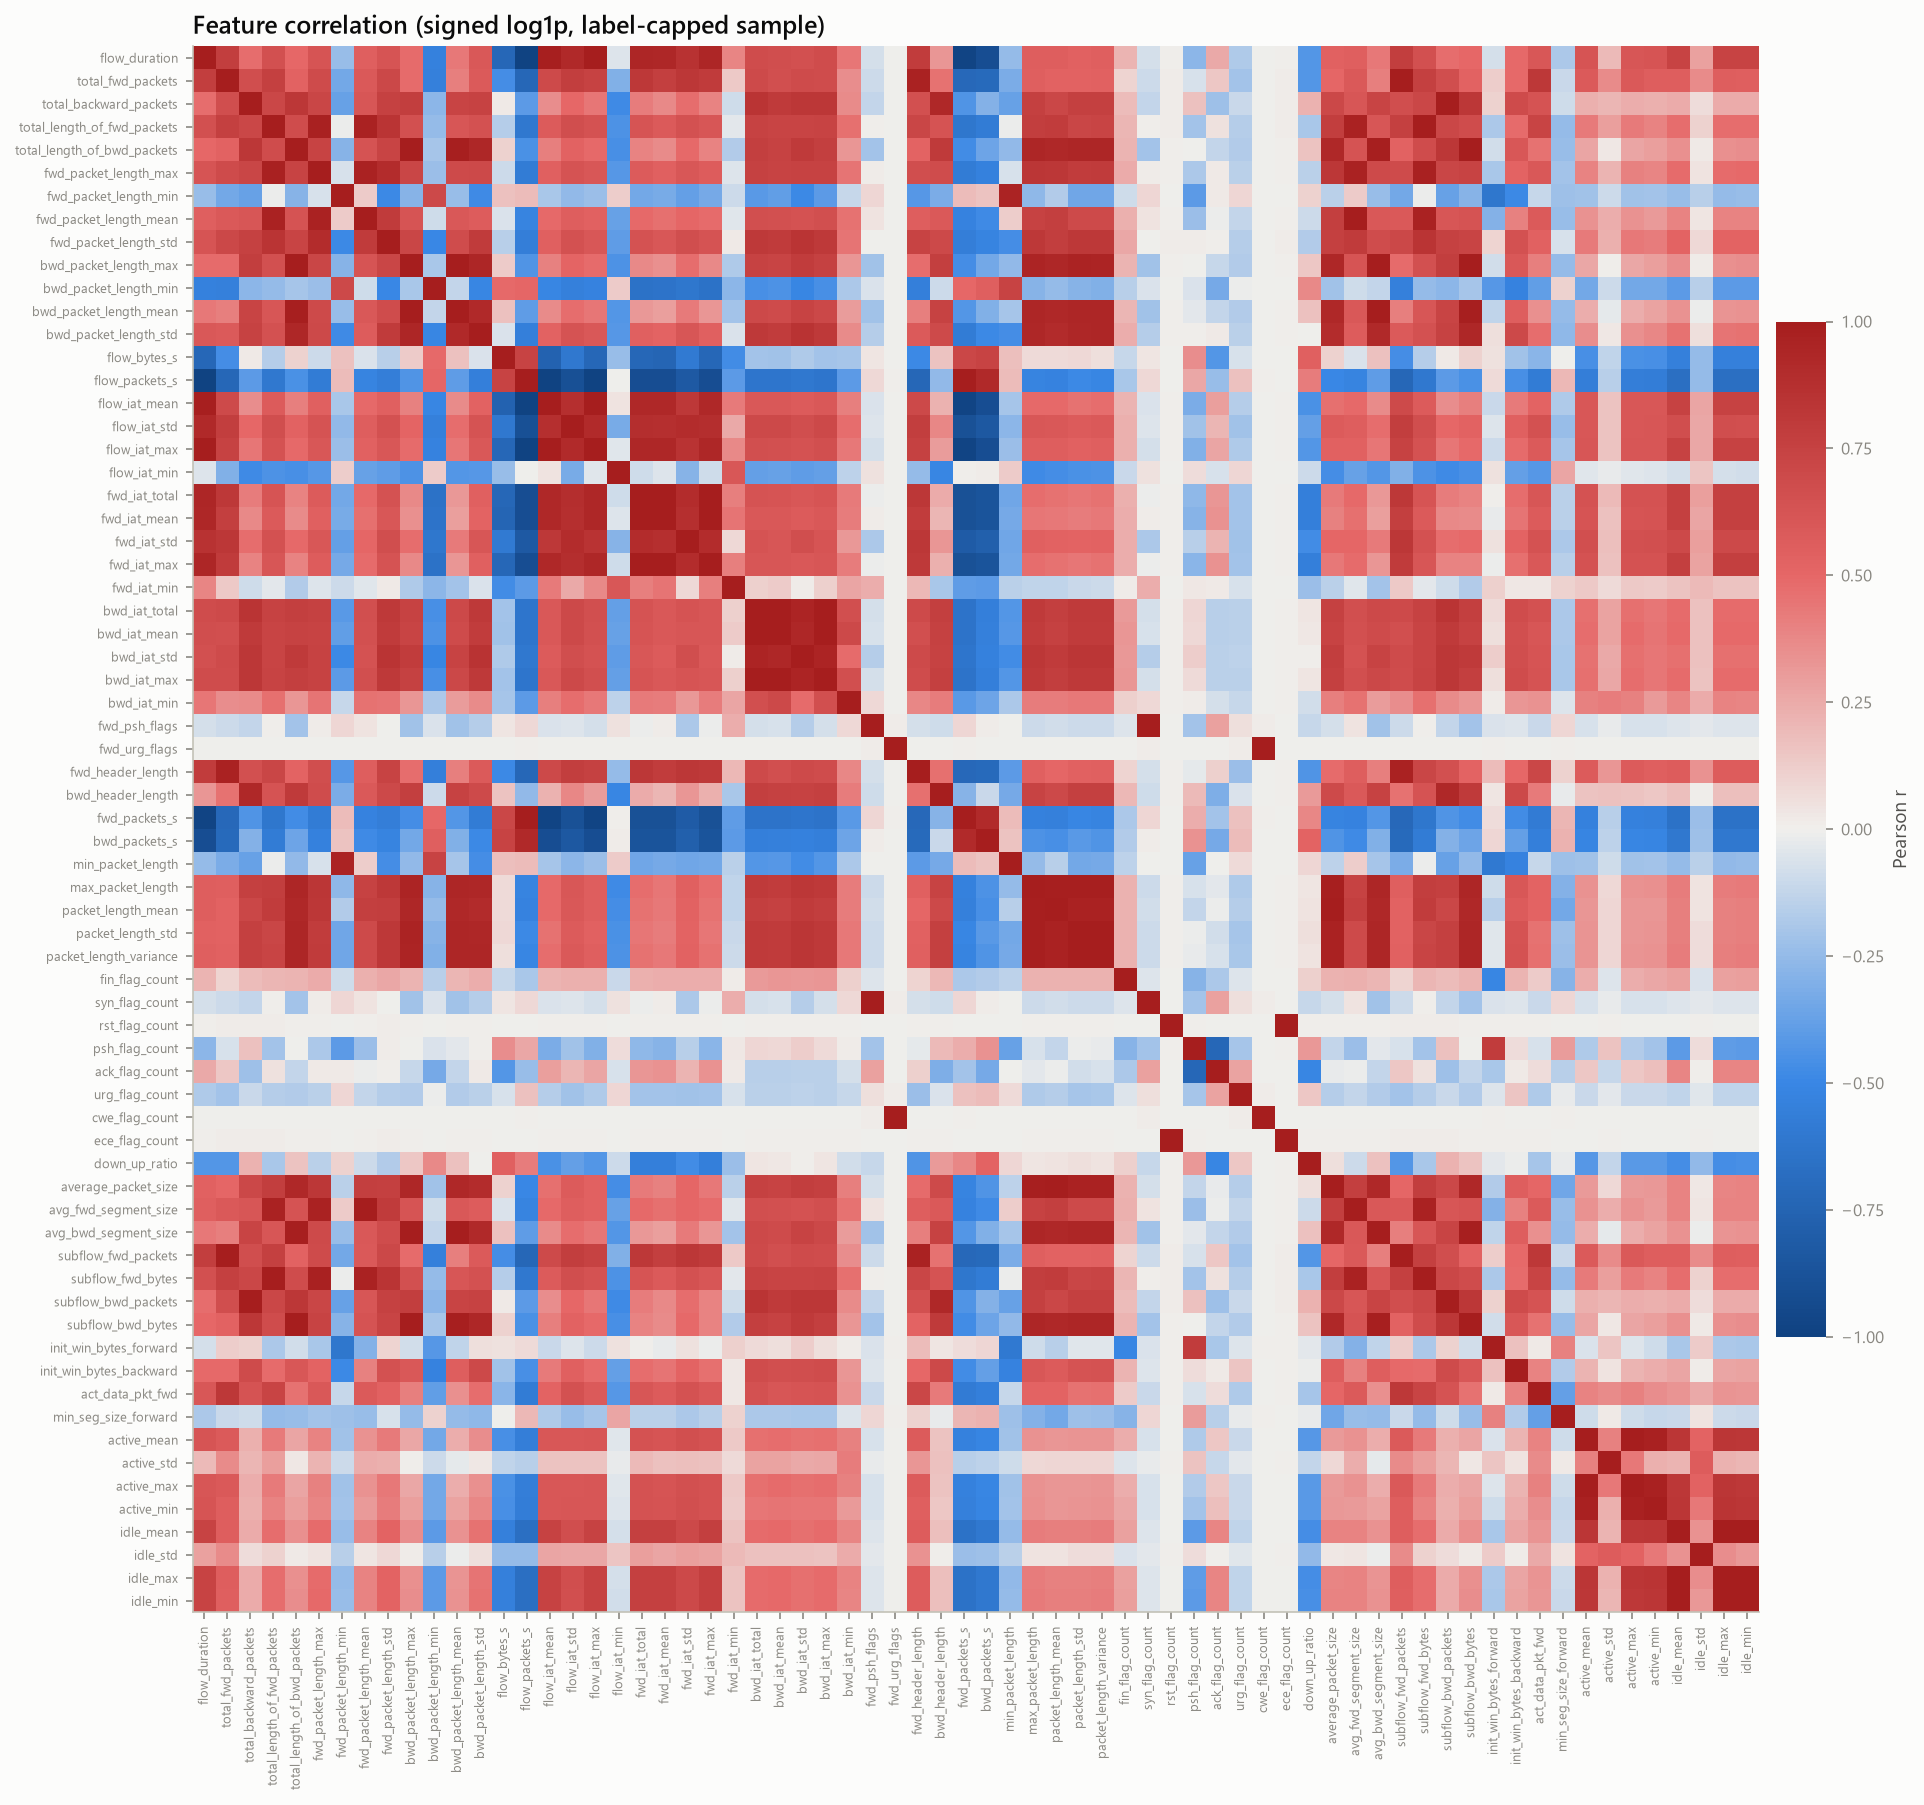

pairs with |r| > 0.9: 118
pairs with |r| > 0.95: 63
pairs with |r| > 0.99: 28
total_fwd_packets            subflow_fwd_packets       1.0000
fwd_packet_length_mean       avg_fwd_segment_size      1.0000
fwd_psh_flags                syn_flag_count            1.0000
bwd_packet_length_mean       avg_bwd_segment_size      1.0000
fwd_urg_flags                cwe_flag_count            1.0000
total_length_of_fwd_packets  subflow_fwd_bytes         1.0000
rst_flag_count               ece_flag_count            1.0000
total_backward_packets       subflow_bwd_packets       1.0000
total_length_of_bwd_packets  subflow_bwd_bytes         1.0000
idle_mean                    idle_max                  0.9998
packet_length_std            packet_length_variance    0.9996
idle_mean                    idle_min                  0.9994


In [8]:
Z = pd.DataFrame(signed_log1p(sample[FEATS].to_numpy('float64')), columns=FEATS)
corr = Z.corr()
viz.corr_heatmap(corr, OUT / 'correlation_heatmap.png', 'Feature correlation (signed log1p, label-capped sample)')
display(Image(OUT / 'correlation_heatmap.png'))
iu = np.triu_indices_from(corr, 1)
pairs = pd.Series(corr.to_numpy()[iu], index=pd.MultiIndex.from_arrays([corr.index[iu[0]], corr.columns[iu[1]]]))
for t in (0.9, 0.95, 0.99): print(f'pairs with |r| > {t}: {(pairs.abs() > t).sum()}')
print(pairs.abs().sort_values(ascending=False).head(12).round(4).to_string())

**Findings.** The feature set is highly redundant. On the label-capped sample, 118 feature pairs have
|r| > 0.9, 63 have |r| > 0.95 and 28 have |r| > 0.99.

* Several pairs are exact copies (r = 1.0000): every `subflow_*` column equals its `total_*`
  counterpart, and `avg_fwd/bwd_segment_size` equals `fwd/bwd_packet_length_mean`.
* Some exact copies are between unrelated flags. `fwd_psh_flags` equals `syn_flag_count`,
  `rst_flag_count` equals `ece_flag_count`, and `fwd_urg_flags` equals `cwe_flag_count`. This
  points to mislabelled flag columns in the published CSVs. It agrees with STEP 4, where CIC
  reported SYN = 0 for flows whose packets clearly contained a SYN.

The preprocessing pipeline removes one feature from each |r| > 0.99 pair, using correlations
computed on the training split only. That drops 21 features for `temporal_per_class`.

## 8. Outliers

Share of flows outside the 1.5 x IQR fences, computed separately for BENIGN and attack flows so that attack traffic is not counted as 'outlier' of benign traffic.

                        BENIGN  Attack
bwd_packet_length_std    0.241   0.022
flow_iat_std             0.236   0.012
fwd_packet_length_std    0.235   0.002
flow_duration            0.233   0.000
bwd_packets_s            0.232   0.224
fwd_iat_max              0.232   0.000
flow_iat_max             0.231   0.000
fwd_iat_total            0.229   0.000
fwd_iat_mean             0.226   0.036
fwd_iat_std              0.221   0.139
bwd_iat_std              0.221   0.156
packet_length_variance   0.218   0.063
max_packet_length        0.215   0.000
bwd_iat_mean             0.213   0.160
bwd_iat_total            0.213   0.217

median outlier share across features: BENIGN 0.171, Attack 0.030


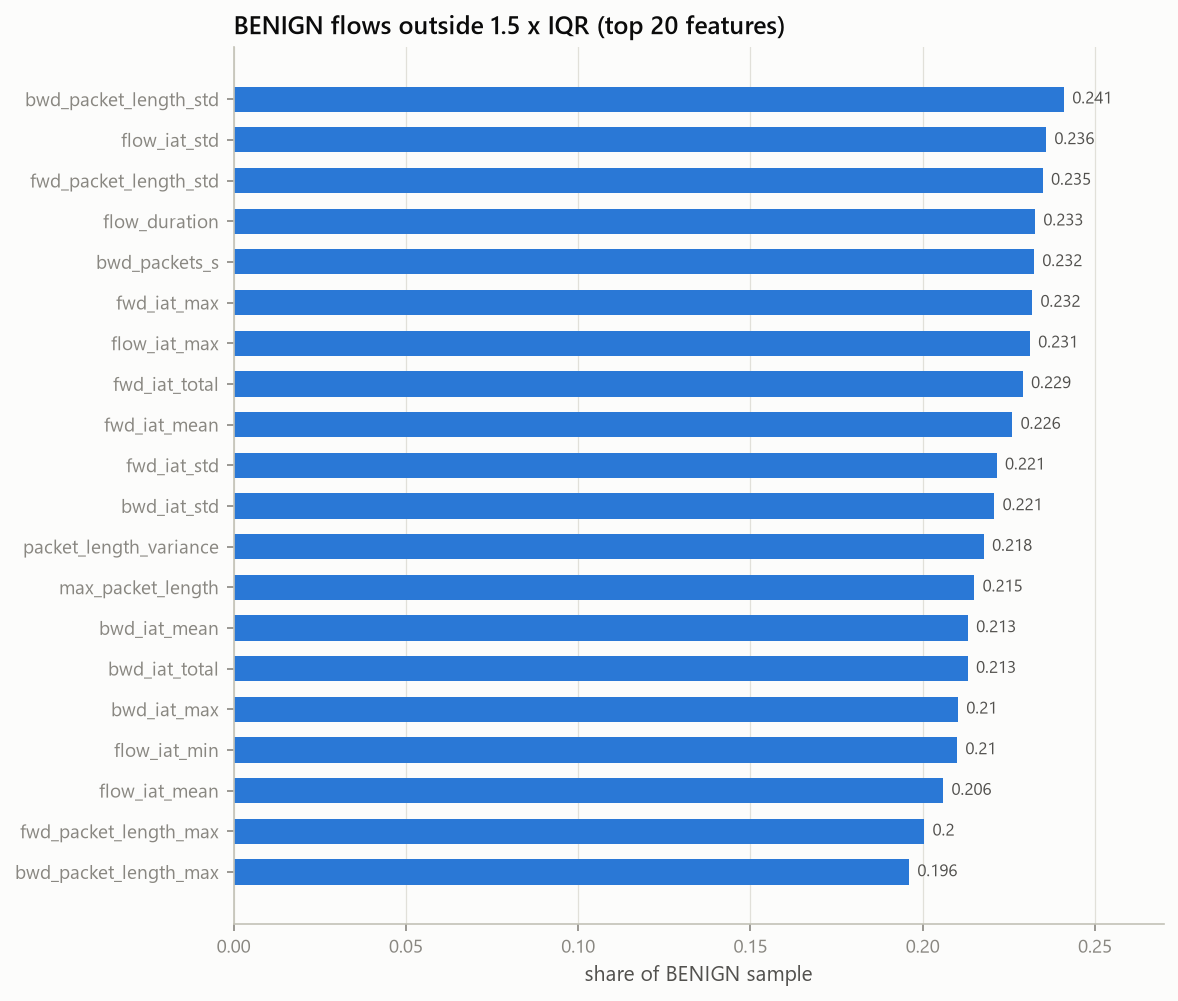

In [9]:
def iqr_share(x):
    q1, q3 = x.quantile(0.25), x.quantile(0.75); r = q3 - q1
    return ((x < q1 - 1.5 * r) | (x > q3 + 1.5 * r)).mean()
out = pd.DataFrame({name: sample.loc[sample.label_binary == k, FEATS].apply(iqr_share) for k, name in [(0, 'BENIGN'), (1, 'Attack')]})
print(out.sort_values('BENIGN', ascending=False).head(15).round(3).to_string())
print(f"\nmedian outlier share across features: BENIGN {out.BENIGN.median():.3f}, Attack {out.Attack.median():.3f}")
viz.bar_counts(out['BENIGN'].sort_values(ascending=False).head(20), 'BENIGN flows outside 1.5 x IQR (top 20 features)',
               'share of BENIGN sample', OUT / 'outliers_benign.png', log=False)
display(Image(OUT / 'outliers_benign.png'))

**Findings.** By the 1.5 x IQR rule, BENIGN traffic is very heavy-tailed: the median feature has 17.1%
of BENIGN flows outside the fences, with timing and length-variability features highest
(e.g. `bwd_packet_length_std` 24.1%, `flow_iat_std` 23.6%, `flow_duration` 23.3%).

Within the attack sample the share is only 3.0%, because each attack tool produces very uniform
flows. Outliers are therefore normal traffic diversity, not errors, and are not removed. The
pipeline uses a signed log1p transform plus RobustScaler instead.

## 9. BENIGN vs attack

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


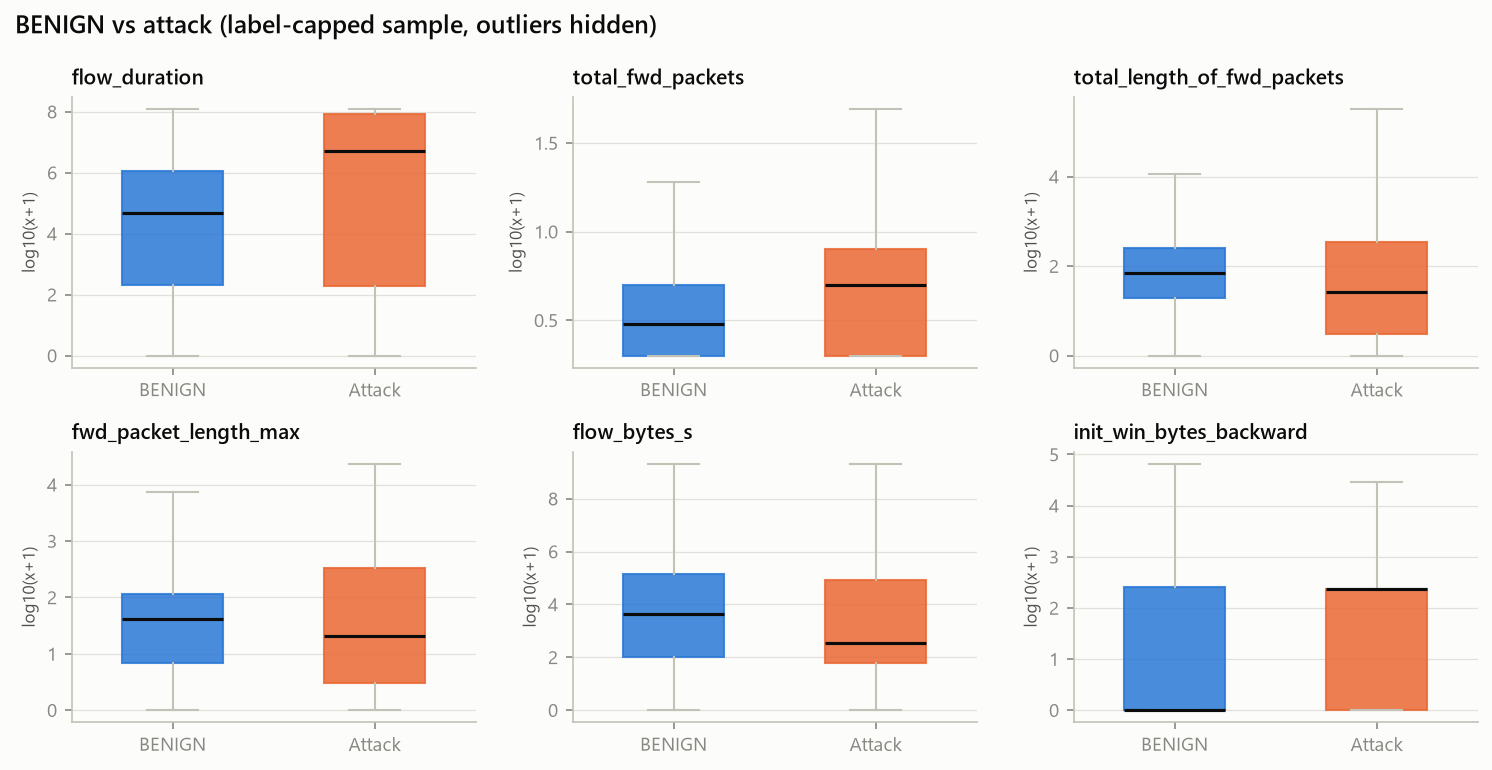

                            flow_duration  total_fwd_packets  total_length_of_fwd_packets  fwd_packet_length_max  flow_bytes_s  init_win_bytes_backward
label                                                                                                                                                  
BENIGN                            46323.0                2.0                         68.0                   41.0        4205.5                     -1.0
Bot                               70987.0                3.0                          6.0                    6.0        5013.1                    237.0
DDoS                            1875323.0                4.0                         26.0                   20.0         160.5                    229.0
DoS GoldenEye                  11587801.0                7.0                        377.0                  370.0         651.0                    235.0
DoS Hulk                       86680684.0                6.0                        354.

  Bot           {8080: 1248, 1841: 1, 1845: 1, 1846: 1, 1847: 1}
  BruteForce    {21: 5932, 22: 3219, 80: 1}
  DDoS          {80: 128010, 64869: 1, 64873: 1, 27636: 1}
  DoS           {80: 193581}
  Heartbleed    {444: 11}
  Infiltration  {444: 36}
  PortScan      {80: 372, 22: 243, 21: 243, 139: 196, 445: 179}
  WebAttack     {80: 2143}


In [10]:
key = ['flow_duration', 'total_fwd_packets', 'total_length_of_fwd_packets', 'fwd_packet_length_max',
       'flow_bytes_s', 'init_win_bytes_backward']
viz.box_compare(sample, key, OUT / 'benign_vs_attack.png', 'BENIGN vs attack (label-capped sample, outliers hidden)')
display(Image(OUT / 'benign_vs_attack.png'))
print(sample.groupby('label')[key].median().round(1).to_string())
print()
print('destination ports, top 5 per attack family:')
for g, x in df[df.label_binary == 1].groupby('label_group'): print(f'  {g:13s}', x.dst_port.value_counts().head(5).to_dict())

**Findings.** Median feature values separate several attack families clearly:

* PortScan: 1 forward packet, 0 payload bytes.
* DoS Slowhttptest and Web Attack Brute Force/XSS: 0 forward payload bytes.
* Heartbleed: 2,792 forward packets and 12,264 bytes in one flow.
* Bot and DDoS: short forward payloads of 6 and 26 bytes.

`init_win_bytes_backward` is a warning sign. Its median is 28,960 for both Web Attack Brute
Force and XSS, and -1 for BENIGN, because the value reflects the TCP stack of the specific
victim server. Destination ports are similarly concentrated:

* DoS, DDoS and Web Attacks: port 80
* Bot: mostly 8080 (1,248 of 1,953)
* Patator: ports 21/22
* Heartbleed and Infiltration: port 444

Port and window features will help on this dataset but may not transfer to other networks.
STEP 10 evaluates this with ablation experiments.

## 10. Feature importance (exploratory)

Random Forest impurity importance, fitted **only on the training split** of the `temporal_per_class` strategy (label-capped sample of it, median imputation from those rows). Correlated features share importance, so this ranks groups rather than single columns; model-based importance and ablations follow in STEP 10.

train rows used: 102,216
init_win_bytes_backward        0.0646
min_seg_size_forward           0.0322
avg_bwd_segment_size           0.0304
fwd_packet_length_max          0.0293
bwd_packets_s                  0.0280
flow_duration                  0.0274
bwd_header_length              0.0266
bwd_packet_length_max          0.0254
packet_length_mean             0.0253
flow_packets_s                 0.0241
fwd_iat_mean                   0.0240
average_packet_size            0.0239
flow_iat_mean                  0.0238
bwd_packet_length_mean         0.0234
init_win_bytes_forward         0.0233
fwd_iat_max                    0.0232
fwd_packet_length_mean         0.0222
flow_iat_std                   0.0221
total_length_of_bwd_packets    0.0221
fwd_iat_total                  0.0218


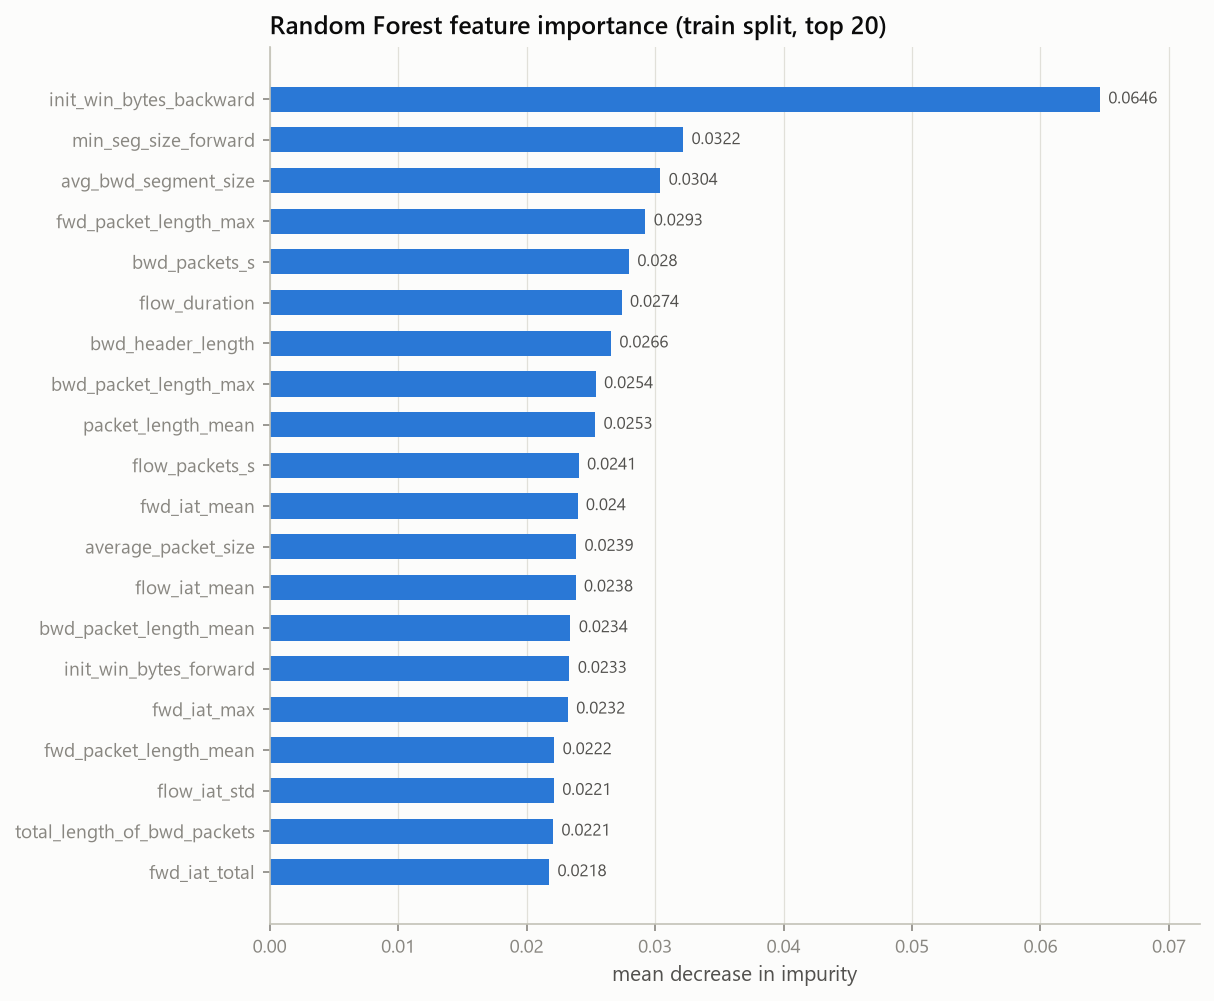

In [11]:
from sklearn.ensemble import RandomForestClassifier
split = split_rows(df[['label', 'timestamp', 'day', 'row_in_file', 'source_file']], 'temporal_per_class', cfg['preprocessing'], SEED)
tr = df[split.to_numpy() == 'train']
tr = capped_sample(tr, 20000)
X = tr[FEATS].fillna(tr[FEATS].median())
rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=SEED, class_weight='balanced')
rf.fit(X, tr.label)
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False)
print(f'train rows used: {len(tr):,}')
print(imp.head(20).round(4).to_string())
viz.bar_counts(imp.head(20), 'Random Forest feature importance (train split, top 20)', 'mean decrease in impurity',
               OUT / 'feature_importance.png', log=False)
display(Image(OUT / 'feature_importance.png'))

**Findings.** On 102,216 label-capped rows from the temporal training split, the Random Forest ranks
`init_win_bytes_backward` first (0.0646), well ahead of the next features: `min_seg_size_forward`
0.0322, `avg_bwd_segment_size` 0.0304 and `fwd_packet_length_max` 0.0293. Importance is spread
across size, rate and timing features after that.

The top feature is the testbed-specific TCP window size noted above, which reinforces the need
for the ablation study. Because correlated features split importance between them, this ranking
is exploratory only.

## 11. Summary

**Findings.** * Cleaned data: 2,498,103 flows, 68 numeric + 2 categorical features, 15 labels in 8 families.
* Data problems handled without using test data:
  * 11.7% exact duplicates and 7,144 label-conflicting rows removed;
  * Inf/NaN/impossible negatives set to NaN and imputed with training medians;
  * 8 constant and 21 near-duplicate (|r| > 0.99) features dropped.
* The imbalance is extreme (188,451 : 1). The three rarest classes have 2-7 test flows, so their
  per-class metrics cannot be estimated reliably. Use class weights or SMOTE on the training
  split, and report macro-F1.
* Attacks are confined to single days, so:
  * multi-class classification uses a temporal per-class split (train on earlier flows, test on
    later ones);
  * unseen-attack evaluation uses a day split (train Mon-Wed, test Thu-Fri).
* Some highly discriminative features (`init_win_bytes_backward`, destination port) reflect the
  testbed configuration and need ablation before any claim of generalisation.